In [38]:
import re
import os
import pandas as pd
import numpy as np
from Bio import SeqIO
from datetime import datetime
from plotnine import *
import geopandas as gpd

In [39]:
# Read in detections dataset 

all_detect_final = pd.read_csv("./metadata/detections_data/combinedNAm_detections_2021-2024.csv", sep = ',')

In [40]:
# Read in sequences dataset (HA)
ha_sequences = pd.read_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha_detectionsgeodata.tsv", sep = '\t')

In [41]:
# Generate a year_month column in both

all_detect_final["year_month"] = all_detect_final["Collection Date"].str.split("-", expand = True)[0] + "_" + all_detect_final["Collection Date"].str.split("-", expand = True)[1]
ha_sequences["year_month"] = ha_sequences["year_only"].astype(str) + "_" + ha_sequences["month_only"].astype(str).str.zfill(2)

In [42]:
# Make a dictionary with counts per year month

per_yearmonth = pd.DataFrame(all_detect_final["year_month"].value_counts()).rename({"year_month":"year_month", "count":"detections"}, axis = 1)
per_yearmonth["sequences"] = ha_sequences["year_month"].value_counts()

In [43]:
# Calculate ratio of sequences to detections

per_yearmonth["ratio"] = per_yearmonth["sequences"] / per_yearmonth["detections"]

In [44]:
# Calculate the percentage of detections per year_month

total_detect = per_yearmonth["detections"].sum()
print(total_detect)
per_yearmonth["pct_detect"] = per_yearmonth["detections"] / total_detect
print(per_yearmonth["pct_detect"].sum()) # This should add up to ~1, its just a check

13335
0.9999999999999998


In [45]:
# Cacluate the smallest ratio of sequences per detections

smallest_ratio = per_yearmonth[per_yearmonth["ratio"].eq(per_yearmonth["ratio"].min())]
print(smallest_ratio)

            detections  sequences  ratio  pct_detect
year_month                                          
2024_09             30        3.0    0.1     0.00225


In [46]:
# If you only have X sequences from that year-month, and that is P percent of the total, what is the total

limiting_sequences = float(smallest_ratio["sequences"].iloc[0]) # limiting sequences is the number of sequences where there is the biggest difference between seq and detect
limiting_pct = float(smallest_ratio["pct_detect"].iloc[0]) # limiting percentage is the percent of detections where there is the biggest difference between seq and detect
avail_seq = limiting_sequences / limiting_pct
print(avail_seq)

1333.4999999999998


In [47]:
# Use the above to determine the total number of sequences you can use

per_yearmonth["seq_to_use_raw"] = per_yearmonth["pct_detect"] * avail_seq
print(per_yearmonth["seq_to_use_raw"].sum())

1333.4999999999998


In [48]:
# Round the sequence number to use to the nearest whole number

per_yearmonth["seq_to_use"] = np.floor(per_yearmonth["seq_to_use_raw"])

# If you're supposed to use 0.0 sequences (rounded), use 1
per_yearmonth.loc[per_yearmonth["seq_to_use"] == 0.0, "seq_to_use"] = 1

print(per_yearmonth["seq_to_use"].sum())

1309.0


In [49]:
print(len(per_yearmonth))
# print(per_yearmonth)

38


In [50]:
per_yearmonth_dict = per_yearmonth.to_dict(orient = "index")
print(per_yearmonth_dict)

{'2022_09': {'detections': 1250, 'sequences': 693.0, 'ratio': 0.5544, 'pct_detect': 0.09373828271466067, 'seq_to_use_raw': 124.99999999999999, 'seq_to_use': 124.0}, '2022_04': {'detections': 1105, 'sequences': 831.0, 'ratio': 0.7520361990950226, 'pct_detect': 0.08286464191976003, 'seq_to_use_raw': 110.49999999999999, 'seq_to_use': 110.0}, '2022_11': {'detections': 1098, 'sequences': 479.0, 'ratio': 0.43624772313296906, 'pct_detect': 0.08233970753655794, 'seq_to_use_raw': 109.79999999999998, 'seq_to_use': 109.0}, '2023_11': {'detections': 1029, 'sequences': 254.0, 'ratio': 0.2468415937803693, 'pct_detect': 0.07716535433070866, 'seq_to_use_raw': 102.89999999999998, 'seq_to_use': 102.0}, '2022_10': {'detections': 902, 'sequences': 343.0, 'ratio': 0.3802660753880266, 'pct_detect': 0.06764154480689914, 'seq_to_use_raw': 90.19999999999999, 'seq_to_use': 90.0}, '2022_05': {'detections': 796, 'sequences': 673.0, 'ratio': 0.8454773869346733, 'pct_detect': 0.05969253843269591, 'seq_to_use_raw': 

In [51]:
per_yearmonth = per_yearmonth.reset_index()

In [52]:
month_order = ["2021_11","2021_12", "2022_01", "2022_02", "2022_03", "2022_04", "2022_05", "2022_06",
               "2022_07", "2022_08", "2022_09", "2022_10", "2022_11", "2022_12","2023_01", "2023_02", "2023_03", "2023_04", 
               "2023_05", "2023_06", "2023_07", "2023_08", "2023_09", "2023_10", "2023_11", "2023_12", "2024_01", "2024_02", 
               "2024_03", "2024_04", "2024_05", "2024_06","2024_07", "2024_08", "2024_09", "2024_10", "2024_11", "2024_12"]

per_yearmonth["year_month"] = pd.Categorical(per_yearmonth["year_month"], categories=month_order, ordered=True)

In [53]:
per_yearmonth.head()

,year_month,detections,sequences,ratio,pct_detect,seq_to_use_raw,seq_to_use
0,2022_09,1250,693.0,0.554400,0.093738,125.0,124.0
1,2022_04,1105,831.0,0.752036,0.082865,110.5,110.0
2,2022_11,1098,479.0,0.436248,0.082340,109.8,109.0
3,2023_11,1029,254.0,0.246842,0.077165,102.9,102.0
4,2022_10,902,343.0,0.380266,0.067642,90.2,90.0


/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:344: PlotnineWarning: position_stack : Removed 1 rows containing missing values.


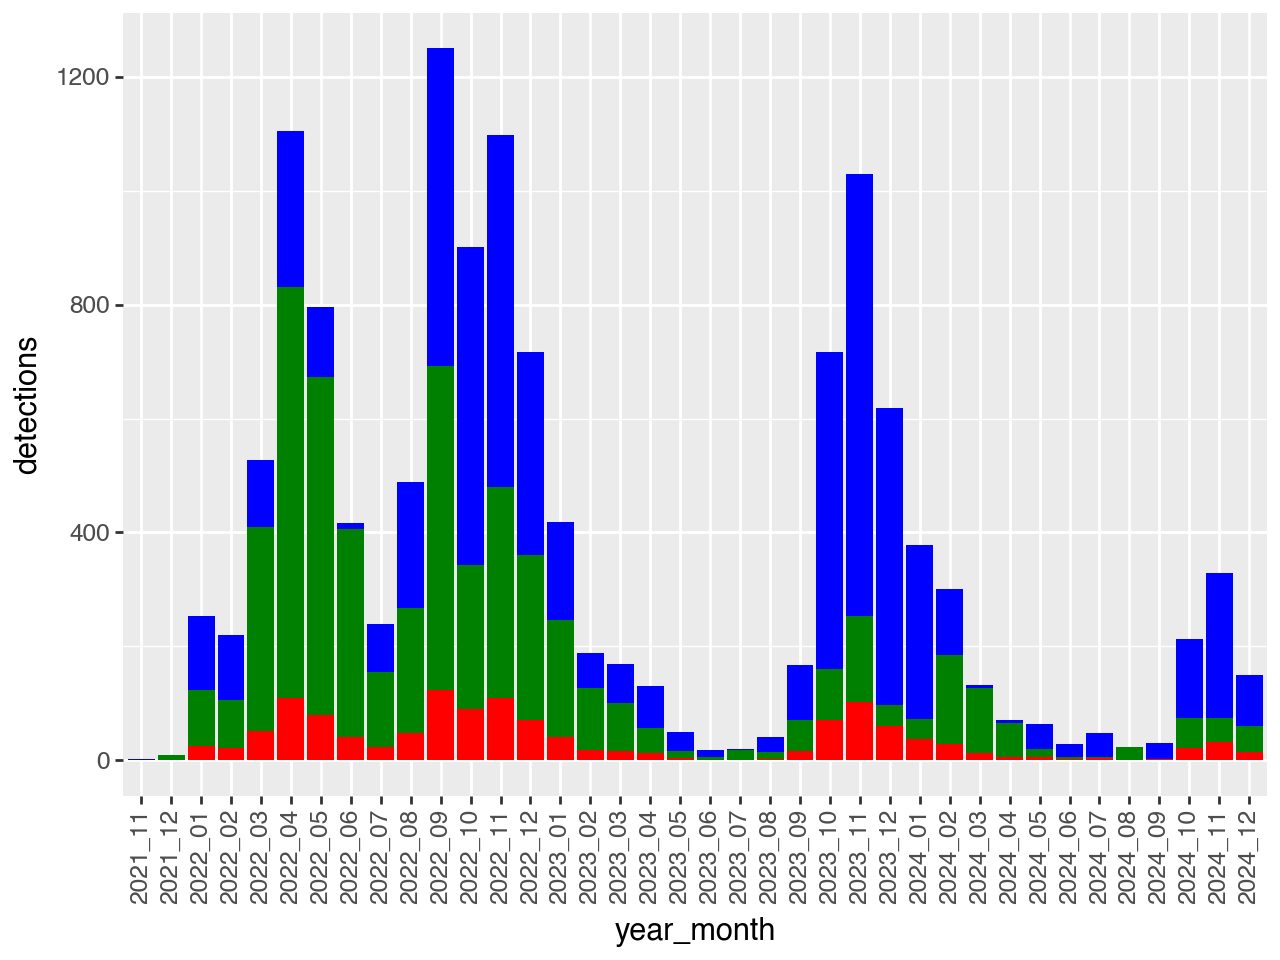

In [54]:
plot = (
    ggplot(per_yearmonth, aes(x = "year_month"))
    + geom_bar(aes(y = "detections"), stat = "identity", fill = "blue")
    + geom_bar(aes(y = "sequences"), stat = "identity", fill = "green")
    + geom_bar(aes(y = "seq_to_use"), stat = "identity", fill = "red")
    + theme(axis_text_x=element_text(rotation=90))
)

plot.show()

In [55]:
# Group detections by year_month and then count locations per year_month

year_month_location = pd.DataFrame(all_detect_final.groupby("year_month")["Location"].value_counts())

In [56]:
# What proportion of each year_month is seen in each location

year_month_location = year_month_location.reset_index() # reset index so you can use it to calculate

for idx, row in year_month_location.iterrows():
    
    time = row["year_month"]
    place = row["Location"]
    count = row["count"]

    total = per_yearmonth_dict[time]["detections"]

    year_month_location.at[idx, "percent_loc_per_yrmon"] = count / total

In [57]:
# Turn this dataframe into a dictionary with the count and percent of this location per year_month detecctions for each year_month and location

location_per_yrmon_dict = {}

for idx, row in year_month_location.iterrows():
    ym = row["year_month"]
    loc = row["Location"]
    count = row["count"]
    percent = row["percent_loc_per_yrmon"]

    if ym not in location_per_yrmon_dict:
        location_per_yrmon_dict[ym] = {}
    
    location_per_yrmon_dict[ym][loc] = {
        "count": count,
        "percent_loc_per_yrmon": percent
    }

In [58]:
# print(location_per_yrmon_dict)

In [59]:
year_month_location.head()

,year_month,Location,count,percent_loc_per_yrmon
0,2021_11,newfoundland,2,1.000000
1,2021_12,newfoundland,4,0.500000
2,2021_12,northcarolina,2,0.250000
3,2021_12,southcarolina,2,0.250000
4,2022_01,northcarolina,125,0.494071


In [60]:
seqperloc_dict = {}

for key in location_per_yrmon_dict:
    yrmon = key
    # print(key)
    
    location_dict = location_per_yrmon_dict[key]
    # print(location_dict)

    locations = list(location_dict)
    # print(locations)

    seqperloc_dict[key] = {}

    for i in locations:
        location_name = i
        pct_detect_per_loc = location_dict[i]["percent_loc_per_yrmon"]
        seq_per_yrmon = per_yearmonth_dict[yrmon]["seq_to_use"]
        seq_per_loc_raw = pct_detect_per_loc * seq_per_yrmon
        # print(i, seq_per_yrmon, seq_per_loc_raw)
       
        seqperloc_dict[key].update({location_name:{"yrmon_seq": seq_per_yrmon, "yrmon_loc_seq_raw": seq_per_loc_raw}}) # Replacing numbers with same per location

In [67]:
#print(seqperloc_dict)

In [68]:
def create_minidict(seqperloc_dict, key):
    mini_dict = {key:{}}

    yrmon = key
    for location in seqperloc_dict[key]:
        seq_per_yrmon_rounded = round(seqperloc_dict[key][location_name]["yrmon_loc_seq_raw"])
        # print(seq_per_yrmon_rounded)
        if seq_per_yrmon_rounded > 0:
            # print(location, "yes", seqperloc_dict[key][location]['yrmon_loc_seq_rounded'])
            pass
        else:
            # print(location, "no")
            mini_dict[key].update({location:seqperloc_dict[key][location]['yrmon_loc_seq_raw']})
    
    return(mini_dict)

In [69]:
mini_dict = create_minidict(seqperloc_dict, "2022_01")
print(mini_dict)

KeyError: 'pennsylvania'

In [70]:
# testy_dict[key].update({location_name:{"yrmon_seq": seq_per_yrmon, "yrmon_loc_seq": seq_per_loc_raw}}) # Replacing numbers with same per location

for key in seqperloc_dict:
    no_locations = len(seqperloc_dict[key])
    sum_seq = per_yearmonth_dict[key]["seq_to_use"]

    for location_name in seqperloc_dict[key]:
        
        seq_per_yrmon = seqperloc_dict[key][location_name]["yrmon_seq"]
        seq_per_yrmon_raw = seqperloc_dict[key][location_name]["yrmon_loc_seq_raw"]
        # print(seq_per_yrmon, seq_per_yrmon_raw)
        
        seq_per_yrmon_rounded = round(seqperloc_dict[key][location_name]["yrmon_loc_seq_raw"])
        seqperloc_dict[key][location_name]["yrmon_loc_seq_rounded"] = seq_per_yrmon_rounded

        # If there is only 1 sequences in that month
        if seq_per_yrmon == 1: 
            
            # If there is 1 sequence per month and one location
            if no_locations == 1: 
                seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = 1 # Take the sequence from that location
            
            # If there is 1 sequence per month but more locations
            elif no_locations > 1: 
                # only_loc = max(seqperloc_dict[key][location_name]["yrmon_loc_seq_raw"], key = lambda k:testy_dict[key][location_name]) # My version
                only_loc = max(seqperloc_dict[key], key=lambda loc: seqperloc_dict[key][loc]["yrmon_loc_seq_raw"]) #Chat GPT's version
                if location_name == only_loc: 
                    seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = 1 # Take the sequence from this location
                else:
                    seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = 0

            else: 
                print("something odd that I didn't expect is happening!")

        # If there is more than one sequence per month, there may be issues with multiple locations with 0 final seqs
        elif seq_per_yrmon > 1:# and no_locations > seq_per_yrmon: 
            if seq_per_yrmon_rounded > 0:
                seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = seq_per_yrmon_rounded
                #pass
            elif seq_per_yrmon_rounded == 0: # for the collection of locations where seq_per_yrmon_rounded is 0
                mini_dict = create_minidict(seqperloc_dict, key)
                # print(mini_dict)
                only_loc = max(mini_dict[key], key=lambda loc: mini_dict[key][loc])
                # print(key, only_loc)
                if location_name == only_loc: 
                    seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = 1 # Take the sequence from this location
                else:
                    seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = 0

In [66]:
#print(seqperloc_dict)

In [71]:
# Now make a new metadata file with the proportional number of samples

In [119]:
def proportional_sampling(df, dictionary):
    
    grouped = df.groupby(["year_month", "division"]) # Group the sequences by month and division

    proportional = [] # Initialize a new list

    for (yr_mon, location), group in ha_sequences_yrmonlocgroup:
    
        if location in dictionary[yr_mon]: # If the location is in the dictionary
            goal_number = dictionary[yr_mon][location]["yrmon_loc_seq_final"] # Set a goal number
        else:
            goal_number = 0

        # if len(group) < number:
        #     print(yr_mon, location, number, len(group))

        # Sometimes there are fewer sequences from that location than I want, so just take all the sequences from that location that I can
        n_to_sample = min(goal_number, len(group))  

        proportional.append(group.sample(n_to_sample, replace = False))

    proportional_df = pd.concat(proportional)

    return(proportional_df)

In [120]:
proportional_seqs = proportional_sampling(ha_sequences, seqperloc_dict)

In [121]:
print(len(proportional_seqs))

1078


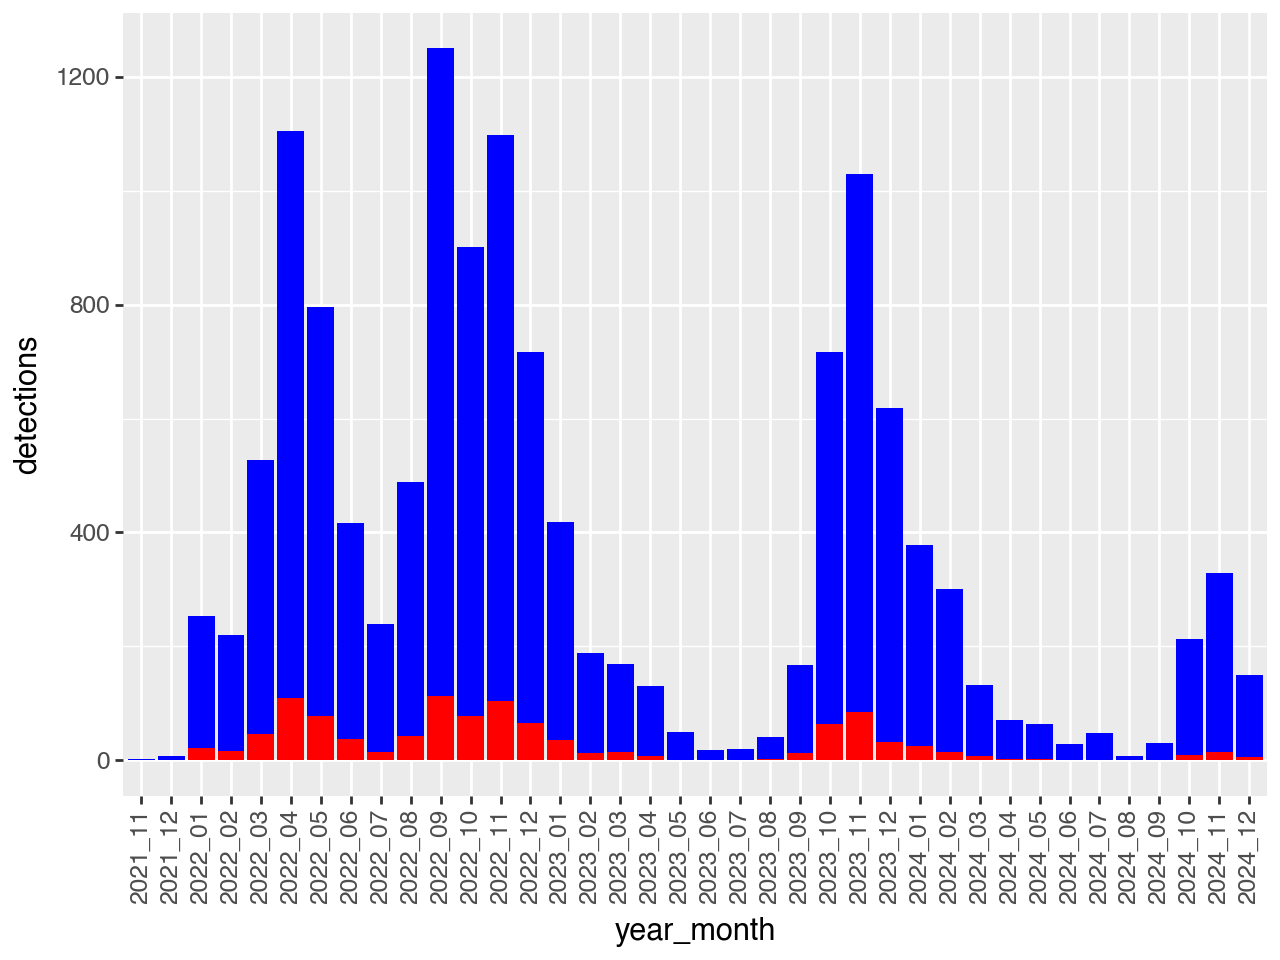

In [131]:
plot2 = (
    ggplot()
    + geom_bar(data = per_yearmonth, mapping= aes(x = "year_month", y = "detections"), stat = "identity", fill = "blue")
    + geom_bar(data = proportional_seqs, mapping = aes(x = "year_month"), stat = "count", fill = "red")
    + theme(axis_text_x=element_text(rotation=90))
)

plot2.show()

In [143]:
proportional_seqs.to_csv("./BEAST/empirical_trees/submission_files/2025-12-05_nov2021-2024_proportional_ha_empirical_targetedbeast/inputs/NAm_wild-aves_nov2021-2024_proportional_ha_metadata.tsv", 
                         sep = "\t")

In [72]:
# Then pull these samples from the big FASTA file

In [136]:
#Function: Read in the FASTA as a dataframe

def fasta_reader(path_to_fasta, output_name):
    fasta_data = []
    FASTANAME = path_to_fasta
        
    with open(FASTANAME) as f:
        header = ""
        sequence = ""
        for line in f:
            if line.startswith(">"):
                if header != "":
                    fasta_data.append({"header": header, "sequence": sequence})
                header = line.strip() 
                sequence = ""
            else:
                sequence += line.strip()
        fasta_data.append({"header": header, "sequence": sequence}) #last line 
        
    globals()[output_name] = pd.DataFrame(fasta_data)

    return

In [137]:
# Function to write a new fasta with just the sequences in the metadata
# Adapted from Maria

def fasta_writer(path, filename, df):
            
    try:  
        os.mkdir(path)

    except OSError as error:
        pass

    with open(f"{path}{filename}", "w") as f:
        for index, row in df.iterrows():
            f.write(f"{row['header']}\n")
            f.write(f"{row['sequence']}\n")

In [138]:
# Function: remove the carrot from the header

def header_to_strain(df):
    df["strain"] = df["header"].str.replace(">","")

    return(df)

In [139]:
# Function: parse to include

def parse_toinclude(objects_list, file_to_parse):
    # Define the list as the objects to include
    to_include = objects_list

    # Filter rows where the 'taxon' value is in the strains_set
    parsed = file_to_parse[file_to_parse["strain"].isin(to_include)]

    return parsed

In [141]:
# List the strain names

list_of_strains = proportional_seqs["strain"].to_list()

fasta_reader("./raw_data/ncbi-bvbrc-gisaid_from-meta_ha.fasta", "ha_fasta")

ha_fasta_strain = header_to_strain(ha_fasta)

parsed_fasta = parse_toinclude(list_of_strains, ha_fasta_strain)

In [142]:
print(len(parsed_fasta))

1078


In [144]:
fasta_writer("./BEAST/empirical_trees/submission_files/2025-12-05_nov2021-2024_proportional_ha_empirical_targetedbeast/inputs/", "NAm_wild-aves_nov2021-2024_proportional_ha_unaligned.fasta", parsed_fasta)

In [ ]:
# Make an alignment on MAFFT